# 01 · EDA: demanda eléctrica del SIN de Bolivia

**Objetivo:** entender la estructura de la demanda horaria del Sistema Interconectado Nacional (SIN) antes de modelar, y medir el error del pronóstico oficial del CNDC (`PREV`), que es el benchmark a batir.

**Datos:** API pública del CNDC (15 min, agregado a horario) y clima de Open-Meteo, de 2024-03-01 en adelante. Se regeneran con `uv run poe data`.

Toda la lógica vive en `src/forecast_energia/`. Este notebook solo la orquesta y muestra los resultados.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from forecast_energia import analysis as A
from forecast_energia import evaluation as E
from forecast_energia import viz
from forecast_energia.data import io

viz.estilo()
pd.set_option("display.float_format", "{:,.2f}".format)

dem = io.cargar_demanda()
gen = io.cargar_generacion()
clima = io.cargar_clima()

sin = io.serie(dem, "SIN")
tot = io.serie(gen, "TOT")
prev = io.serie(gen, "PREV")
print(f"Rango: {sin.index.min():%Y-%m-%d} → {sin.index.max():%Y-%m-%d}  ({len(sin):,} horas)")

Rango: 2024-03-01 → 2026-10-16  (23,040 horas)


## 1. Calidad de los datos y conciliación con la generación

La API publica dos mediciones independientes: la **demanda por departamento** (`rt/demanda`) y la **generación total** (`rt/generacion`, `TOT`). Comparar su cociente permite auditar los datos departamentales.

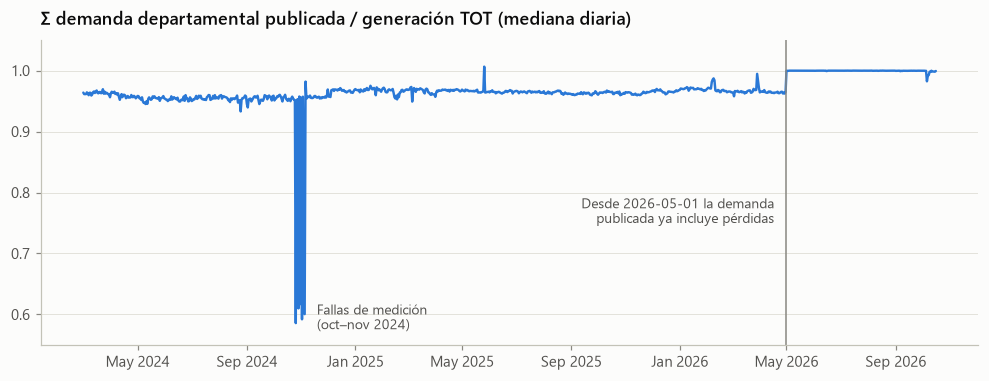

In [2]:
crudo = io.a_ancho(dem, "y_medido").drop(columns="SIN")
ratio = (crudo.sum(axis=1, min_count=8) / tot).dropna()
ratio_dia = ratio.groupby(ratio.index.normalize()).median()

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(ratio_dia.index, ratio_dia, color=viz.CATEGORICA[0], lw=1.6)
ax.axvline(pd.Timestamp("2026-05-01"), color=viz.TINTA_SUAVE, lw=1)
ax.annotate(
    "Desde 2026-05-01 la demanda\npublicada ya incluye pérdidas",
    (pd.Timestamp("2026-05-01"), 0.75),
    xytext=(-8, 0),
    textcoords="offset points",
    ha="right",
    fontsize=9,
    color=viz.TINTA_2,
)
ax.annotate(
    "Fallas de medición\n(oct–nov 2024)",
    (pd.Timestamp("2024-10-29"), ratio_dia["2024-10-20":"2024-11-10"].min()),
    xytext=(12, -4),
    textcoords="offset points",
    fontsize=9,
    color=viz.TINTA_2,
)
ax.set(
    title="Σ demanda departamental publicada / generación TOT (mediana diaria)", ylim=(0.55, 1.05)
)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
viz.guardar(fig, "eda_calidad_ratio_tot");

In [3]:
calidad = (
    dem.groupby("unique_id")
    .agg(
        media_MW=("y", "mean"),
        pct_imputado=("imputado", lambda x: 100 * x.mean()),
        horas_nan=("y", lambda y: y.isna().sum()),
    )
    .sort_values("media_MW", ascending=False)
)
calidad["participacion_%"] = 100 * calidad["media_MW"] / calidad.loc["SIN", "media_MW"]
calidad

,media_MW,pct_imputado,horas_nan,participacion_%
unique_id,,,,
SIN,"1,346.01",1.55,12,100.00
SANTA CRUZ,544.92,1.33,12,40.48
LA PAZ,256.17,1.33,12,19.03
COCHABAMBA,204.53,1.33,12,15.20
POTOSI,139.63,1.33,12,10.37
ORURO,79.36,1.35,12,5.90
TARIJA,54.42,1.37,12,4.04
CHUQUISACA,44.40,1.33,12,3.30
BENI,22.57,1.48,12,1.68


Se encontraron dos problemas que **habrían contaminado cualquier modelo** entrenado sobre los datos crudos:

1. **Cambio de definición el 2026-05-01.** Antes, Σ deptos ≈ 0.96 × TOT (demanda sin pérdidas). Desde esa fecha Σ deptos = TOT. Usados en crudo, se vería un salto artificial de +4 % justo en el periodo de test.
2. **Fallas de medición departamentales** (sobre todo oct–nov 2024): Beni, Oruro, Tarija y Potosí aparecen con ~0 MW en días alternos, mientras la generación total es normal.

**Solución** (`processing.detectar_anomalias_departamentales`, `imputar_por_participacion`, `ajustar_a_tot`):
- Se marcan como anómalas las horas en que el cociente se aleja más del 5 % de su nivel local, o un departamento cae fuera de [0.4, 2.5] × su mediana horaria reciente.
- Esas horas se imputan como *participación típica del departamento × TOT* (~1.3 % de las horas).
- Los departamentos se reescalan para que **Σ deptos = TOT exactamente**. Así tienen una definición constante (demanda + pérdidas asignadas en proporción) y la jerarquía cierra.

**Resultado:** el SIN es igual a la generación `TOT`, que es la misma magnitud que pronostica el CNDC. Solo quedan 12 horas sin dato, que también faltan en `TOT`.

## 2. Tendencia y estacionalidad anual

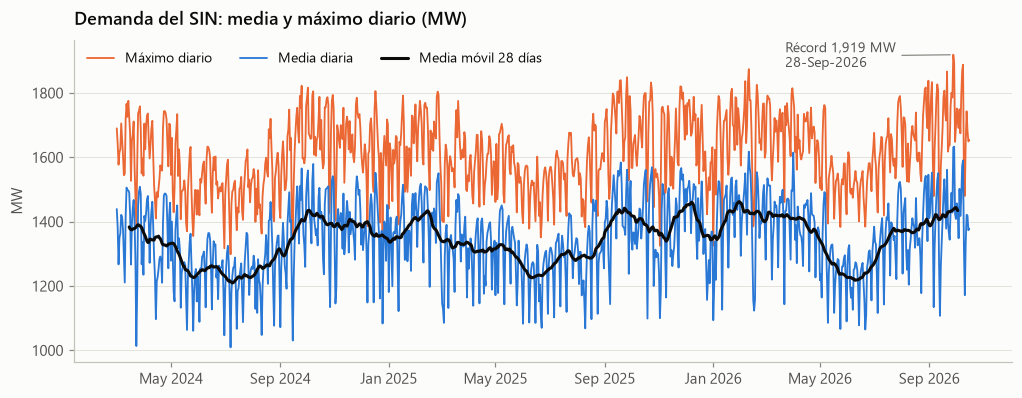

In [4]:
d = A.diaria(sin)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(d.index, d["max"], color=viz.CATEGORICA[1], lw=1.2, label="Máximo diario")
ax.plot(d.index, d["media"], color=viz.CATEGORICA[0], lw=1.2, label="Media diaria")
ax.plot(
    d.index,
    d["media"].rolling(28, center=True).mean(),
    color=viz.TINTA,
    lw=2,
    label="Media móvil 28 días",
)
pico = d["max"].idxmax()
ax.annotate(
    f"Récord {d['max'].max():,.0f} MW\n{pico:%d-%b-%Y}",
    xy=(pico, d["max"].max()),
    xytext=(-110, -8),
    textcoords="offset points",
    fontsize=9,
    color=viz.TINTA_2,
    arrowprops=dict(arrowstyle="-", color=viz.TINTA_SUAVE, lw=0.8),
)
ax.set(title="Demanda del SIN: media y máximo diario (MW)", ylabel="MW")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="upper left", ncols=3)
viz.guardar(fig, "eda_serie_sin");

In [5]:
mensual = d["media"].resample("MS").mean()
crecimiento = (100 * (mensual / mensual.shift(12) - 1)).dropna()
print(
    f"Crecimiento interanual medio de la demanda: {crecimiento.mean():.1f} % "
    f"(rango {crecimiento.min():.1f} % a {crecimiento.max():.1f} %)"
)

Crecimiento interanual medio de la demanda: 1.7 % (rango -4.3 % a 8.0 %)


- **Crece ~1.7 % interanual en promedio** (rango −4 % a +8 % según el mes). Ojo: con los datos crudos parecía 3.6 %, inflado por el cambio de definición. Los modelos necesitan un nivel que se adapte, no basta una estacionalidad fija.
- Estacionalidad anual suave: la demanda es más alta en la época cálida (sep–mar), cuando sube el aire acondicionado en el oriente.
- Solo hay ~2.6 años de historia, poco para estimar la estacionalidad anual. **El clima la sustituye** como variable explicativa.

## 3. Estacionalidad diaria y semanal

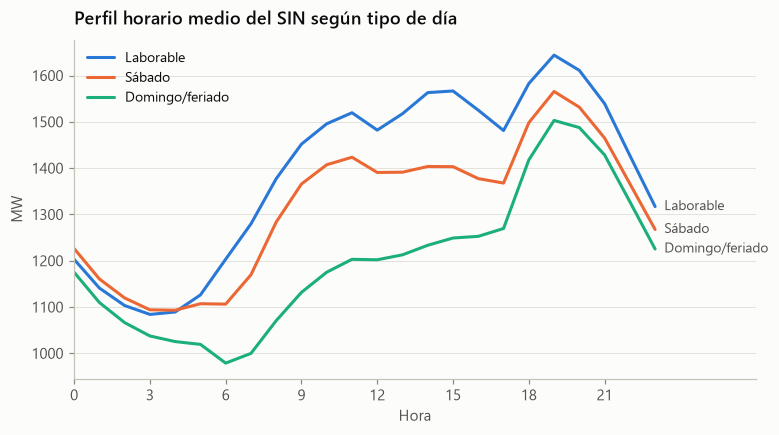

In [6]:
perfil = A.perfil_horario(sin)
fig, ax = plt.subplots(figsize=(8, 4))
for tipo in ["Laborable", "Sábado", "Domingo/feriado"]:
    ax.plot(perfil.index, perfil[tipo], color=viz.COLOR_TIPO_DIA[tipo], label=tipo)
    viz.etiqueta_final(ax, 23, perfil[tipo].iloc[-1], tipo)
ax.set(
    title="Perfil horario medio del SIN según tipo de día",
    xlabel="Hora",
    ylabel="MW",
    xticks=range(0, 24, 3),
    xlim=(0, 27),
)
ax.legend(loc="upper left")
viz.guardar(fig, "eda_perfil_horario");

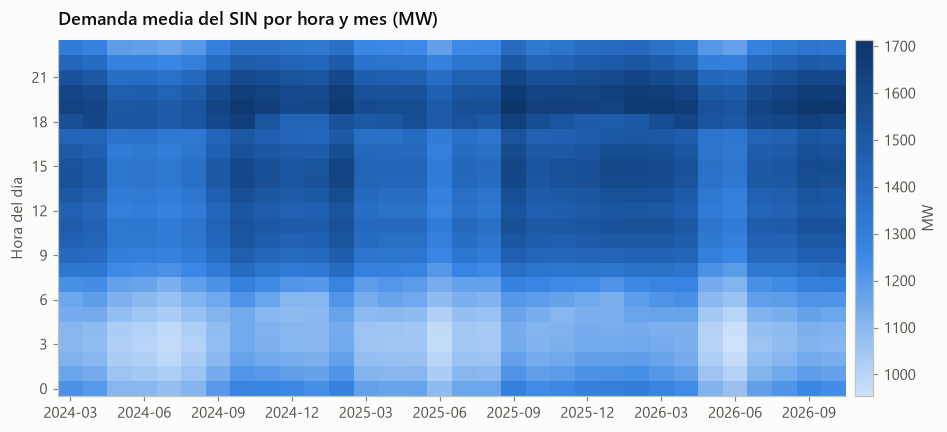

In [7]:
hm = A.heatmap_hora_mes(sin)
fig, ax = plt.subplots(figsize=(11, 4.2))
im = ax.imshow(hm.to_numpy(), aspect="auto", cmap=viz.SECUENCIAL, origin="lower")
ax.set_xticks(range(0, hm.shape[1], 3), [str(p) for p in hm.columns[::3]], rotation=0)
ax.set_yticks(range(0, 24, 3))
ax.set(title="Demanda media del SIN por hora y mes (MW)", ylabel="Hora del día")
ax.grid(False)
fig.colorbar(im, ax=ax, pad=0.01, label="MW")
viz.guardar(fig, "eda_heatmap_hora_mes");

- **Doble pico:** uno a mediodía (comercio y aire acondicionado) y el **pico principal a las 19–20 h** (iluminación residencial). El valle está a las 4 h.
- Domingos y feriados bajan cerca de un 20 % a mediodía. El sábado queda en un punto intermedio. **El tipo de día es una variable clave.**
- En el heatmap, los meses fríos (may–ago) bajan la demanda en todas las horas: la estacionalidad anual viene del clima del oriente (sección 5).

## 4. Efecto de los feriados

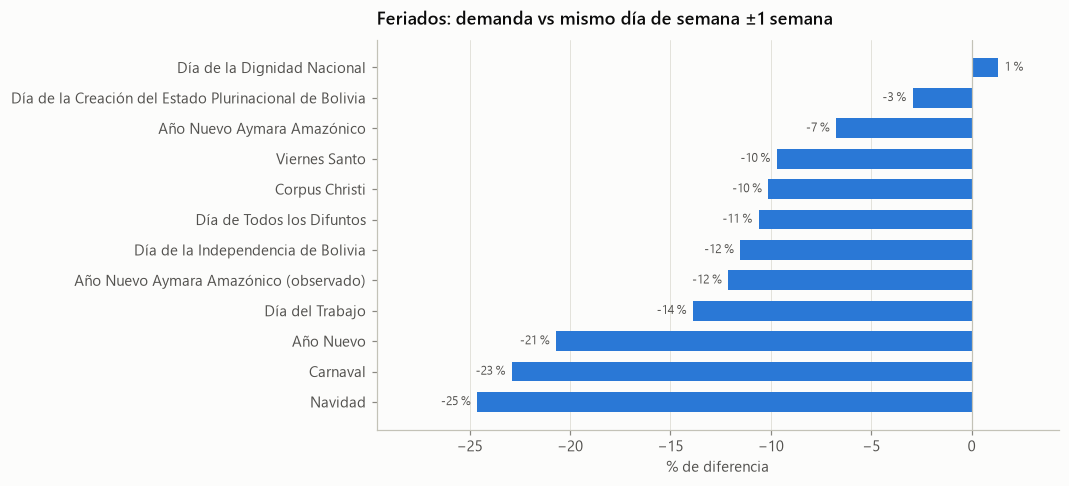

In [8]:
fer = A.efecto_feriados(sin)
resumen = fer.groupby("feriado")["pct"].mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(resumen.index, resumen.values, color=viz.CATEGORICA[0], height=0.65)
ax.axvline(0, color=viz.EJE, lw=0.8)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
for y, v in enumerate(resumen.values):
    ax.annotate(
        f"{v:.0f} %",
        (v, y),
        xytext=(-4 if v < 0 else 4, 0),
        textcoords="offset points",
        ha="right" if v < 0 else "left",
        va="center",
        fontsize=8,
        color=viz.TINTA_2,
    )
ax.set(
    title="Feriados: demanda vs mismo día de semana ±1 semana",
    xlabel="% de diferencia",
    xlim=(resumen.min() - 5, max(resumen.max(), 0) + 3),
)
viz.guardar(fig, "eda_feriados");

- Navidad, Carnaval, Año Nuevo y Todos Santos recortan la demanda en ~20–25 %. Es un error enorme si el modelo no los conoce.
- Se usarán `es_feriado`, `pre_feriado` y `post_feriado`, además de los **feriados departamentales** (p.ej. 24-sep en Santa Cruz) para los modelos por departamento.

## 5. Clima: ¿qué departamentos dependen de la temperatura?

In [9]:
corr = A.correlacion_clima_por_depto(dem, clima).sort_values("corr", ascending=False)
corr.rename(
    columns={
        "temp_media": "T media (°C)",
        "corr": "corr. anomalías",
        "pct_por_grado": "% demanda por °C",
    }
)

,T media (°C),corr. anomalías,% demanda por °C
departamento,,,
BENI,25.60,0.89,5.77
SANTA CRUZ,23.37,0.76,2.59
TARIJA,15.81,0.42,0.78
COCHABAMBA,16.59,0.25,0.61
CHUQUISACA,13.65,0.24,0.94
POTOSI,7.91,0.05,0.19
ORURO,9.64,0.04,0.17
LA PAZ,9.61,-0.07,-0.18


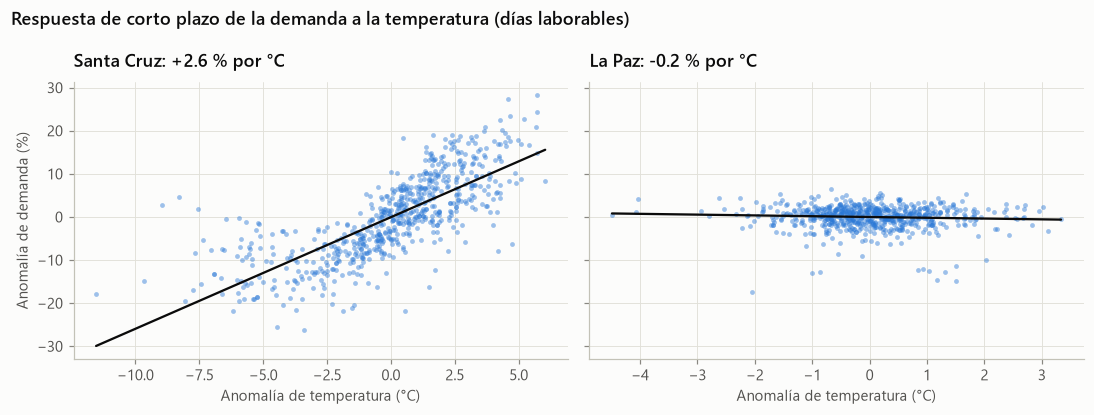

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, dep in zip(axes, ["SANTA CRUZ", "LA PAZ"], strict=True):
    temp = clima.loc[clima.unique_id == dep].set_index("ds")["temperature_2m"]
    s = A.sensibilidad_temperatura(io.serie(dem, dep), temp)
    ax.scatter(
        s["temp_anom"], s["demanda_anom_pct"], s=10, color=viz.CATEGORICA[0], alpha=0.45, lw=0
    )
    b, a = np.polyfit(s["temp_anom"], s["demanda_anom_pct"], 1)
    xs = np.linspace(s["temp_anom"].min(), s["temp_anom"].max(), 10)
    ax.plot(xs, a + b * xs, color=viz.TINTA, lw=1.5)
    ax.set(title=f"{dep.title()}: {b:+.1f} % por °C", xlabel="Anomalía de temperatura (°C)")
    ax.grid(axis="x")
axes[0].set_ylabel("Anomalía de demanda (%)")
fig.suptitle(
    "Respuesta de corto plazo de la demanda a la temperatura (días laborables)",
    x=0.01,
    ha="left",
    fontweight="semibold",
)
fig.tight_layout()
viz.guardar(fig, "eda_clima_temperatura");

- **Oriente cálido (Santa Cruz y Beni):** correlación de 0.76–0.89, con **+2.6 % y +5.8 % de demanda por cada °C** de anomalía, por el aire acondicionado.
- **Altiplano (La Paz, Oruro, Potosí):** correlación ~0, sin respuesta a la temperatura.
- Valles (Tarija, Cochabamba, Chuquisaca): respuesta débil a moderada (0.6–0.9 % por °C).
- Como Santa Cruz pesa ~40 % del SIN, **la temperatura de Santa Cruz es la exógena más importante para el SIN.** Se usará su pronóstico hecho 48 h antes (`temperature_2m_d2`) para no tener leakage.

## 6. Mix de generación

unique_id,Hidro,Térmica,Eólica,Solar,Otras
% del total,26.19,65.14,3.11,3.03,2.54


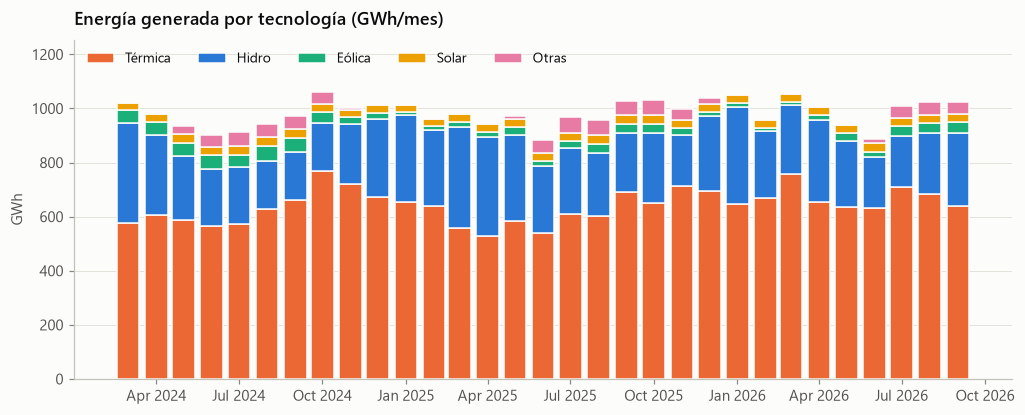

In [11]:
mix = A.mix_mensual(gen)
fig, ax = plt.subplots(figsize=(11, 4))
base = np.zeros(len(mix))
for tec in ["Térmica", "Hidro", "Eólica", "Solar", "Otras"]:
    ax.bar(
        mix.index,
        mix[tec],
        width=25,
        bottom=base,
        color=viz.COLOR_TECNOLOGIA[tec],
        label=tec,
        edgecolor=viz.SUPERFICIE,
        linewidth=1,
    )
    base += mix[tec].fillna(0).to_numpy()
ax.set(
    title="Energía generada por tecnología (GWh/mes)",
    ylabel="GWh",
    ylim=(0, mix.sum(axis=1).max() * 1.18),
)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="upper left", ncols=5)
viz.guardar(fig, "eda_mix_generacion")
(mix.div(mix.sum(axis=1), axis=0) * 100).mean().rename("% del total").to_frame().T

- **El sistema es mayoritariamente térmico (~65 %, a gas).** La hidro aporta ~25 %, con un pico en la época de lluvias (dic–abr). Solar y eólica suman ~6 %.
- Con tan poca renovable variable, la incertidumbre del sistema viene sobre todo **de la demanda**, lo que confirma la elección del objetivo. Cada MW mal pronosticado se cubre con térmica de reserva, y ese es el costo que se busca reducir.

## 7. Benchmark: el pronóstico oficial del CNDC (`PREV`)

`PREV` es el predespacho del CNDC y **pronostica la generación total (`TOT`)**. Tras la conciliación de la sección 1, nuestro SIN es igual a `TOT`, así que la comparación es directa.

El CNDC publica el predespacho con 1–2 días de anticipación. Para competir en igualdad, **nuestros modelos solo podrán usar datos hasta las 24:00 del día D−2** al pronosticar el día D, es decir, un horizonte de 24–47 h. Por eso el naive válido es el de 48 h o el de 168 h, no el de 24 h.

In [12]:
pronosticos = {
    "PREV (CNDC)": prev,
    "Naive 168 h (semana anterior)": tot.shift(168),
    "Naive 48 h": tot.shift(48),
}
ultimos_6m = tot.index >= tot.index.max() - pd.DateOffset(months=6)
pd.concat(
    {
        "Todo el periodo": E.tabla_metricas(tot, pronosticos),
        "Últimos 6 meses": E.tabla_metricas(tot[ultimos_6m], pronosticos),
    },
).drop(columns="n")

MAE   RMSE  MAPE  sesgo
Todo el periodo PREV (CNDC)                    52.00  67.64  3.88   2.36
                Naive 168 h (semana anterior)  89.67 120.50  6.69   0.35
                Naive 48 h                    120.01 163.63  9.16   0.08
Últimos 6 meses PREV (CNDC)                    54.86  70.55  4.09   7.17
                Naive 168 h (semana anterior)  83.24 110.70  6.12   1.82
                Naive 48 h                    116.31 158.71  8.89   0.86

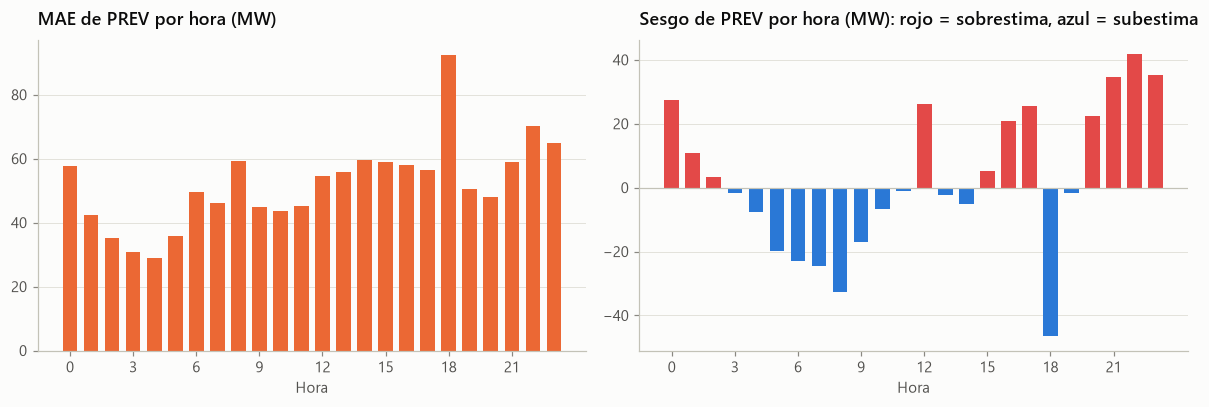

In [13]:
por_hora = E.error_por_grupo(tot, prev, pd.Series(tot.index.hour, index=tot.index))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(por_hora.index, por_hora["MAE"], color=viz.COLOR_PREV, width=0.7)
axes[0].set(title="MAE de PREV por hora (MW)", xlabel="Hora", xticks=range(0, 24, 3))
colores = [viz.CATEGORICA[0] if v < 0 else viz.CATEGORICA[7] for v in por_hora["sesgo"]]
axes[1].bar(por_hora.index, por_hora["sesgo"], color=colores, width=0.7)
axes[1].axhline(0, color=viz.EJE, lw=0.8)
axes[1].set(
    title="Sesgo de PREV por hora (MW): rojo = sobrestima, azul = subestima",
    xlabel="Hora",
    xticks=range(0, 24, 3),
)
fig.tight_layout()
viz.guardar(fig, "eda_prev_error_hora");

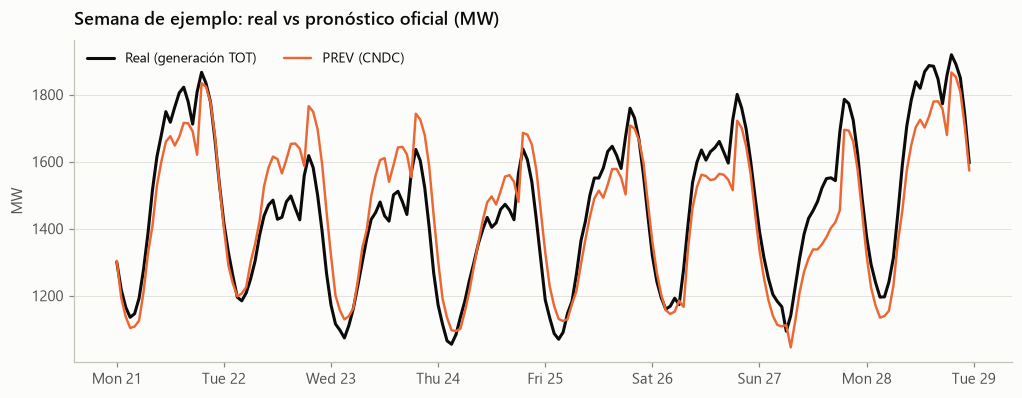

In [14]:
semana = slice("2026-09-21", "2026-09-28")
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(tot[semana].index, tot[semana], color=viz.COLOR_REAL, lw=2, label="Real (generación TOT)")
ax.plot(prev[semana].index, prev[semana], color=viz.COLOR_PREV, lw=1.6, label="PREV (CNDC)")
ax.set(title="Semana de ejemplo: real vs pronóstico oficial (MW)", ylabel="MW")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d"))
ax.legend(loc="upper left", ncols=2)
viz.guardar(fig, "eda_prev_semana");

- **`PREV` tiene un MAPE de ~3.9 % (MAE ~52 MW)**, muy por delante de los naive (6.7 % y 9.2 %). Es un benchmark exigente.
- El error se concentra en las **rampas**: a las 18–19 h subestima la subida del pico vespertino (sesgo ≈ −47 MW) y a las 21–00 h sobrestima la bajada. Hay un patrón sistemático por hora que un modelo con hora × tipo de día × clima puede corregir.

## 8. ¿Por qué un pronóstico probabilístico?

Intervalo empírico 90 % del error: [-103, +120] MW
Ancho del intervalo 90 % por hora: mín 116 MW (h 4), máx 317 MW (h 18)


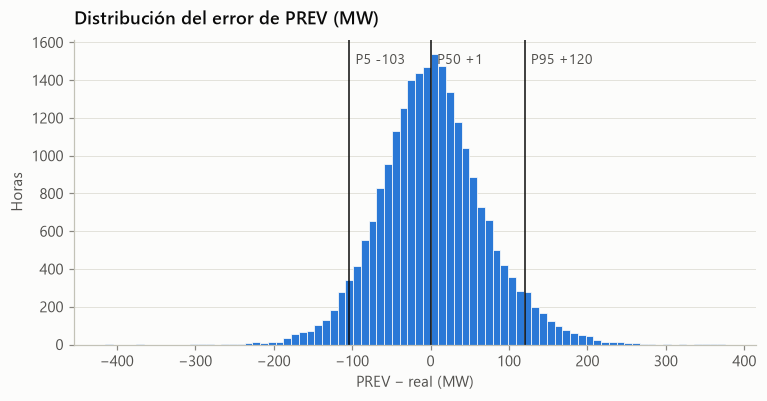

In [15]:
err = (prev - tot).dropna()
q = err.quantile([0.05, 0.5, 0.95])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(err, bins=80, color=viz.CATEGORICA[0], edgecolor=viz.SUPERFICIE, linewidth=0.5)
for v, lab in zip(q.values, ["P5", "P50", "P95"], strict=True):
    ax.axvline(v, color=viz.TINTA, lw=1)
    ax.annotate(
        f"{lab} {v:+.0f}",
        (v, ax.get_ylim()[1] * 0.92),
        xytext=(4, 0),
        textcoords="offset points",
        fontsize=9,
        color=viz.TINTA_2,
    )
ax.set(title="Distribución del error de PREV (MW)", xlabel="PREV − real (MW)", ylabel="Horas")
viz.guardar(fig, "eda_prev_distribucion_error")
ancho_90 = err.groupby(err.index.hour).quantile(0.95) - err.groupby(err.index.hour).quantile(0.05)
print(f"Intervalo empírico 90 % del error: [{q[0.05]:+.0f}, {q[0.95]:+.0f}] MW")
print(
    f"Ancho del intervalo 90 % por hora: mín {ancho_90.min():.0f} MW (h {ancho_90.idxmin()}), máx {ancho_90.max():.0f} MW (h {ancho_90.idxmax()})"
)

- El 90 % de las horas, el error de `PREV` cae entre −103 y +120 MW. Ese margen es el **que el operador debe cubrir con reserva**, y hoy no se comunica explícitamente.
- La incertidumbre **depende mucho de la hora**: el intervalo del 90 % mide 116 MW a las 4 h y 317 MW a las 18 h. Un intervalo de ancho fijo sobrecubre de madrugada y subcubre al anochecer. Esto motiva **intervalos condicionales** (CQR / conformal por hora).

## 9. Conclusiones para el modelado

| Hallazgo | Decisión |
|---|---|
| Doble estacionalidad diaria (24 h) y semanal (168 h) | MSTL(24, 168), lags 48/168 y features de hora × día de semana |
| Feriados nacionales: −10 a −25 % | `es_feriado`, `pre_feriado`, `post_feriado` (+ departamentales en el modelo jerárquico) |
| Tendencia suave (~+1.7 %/año) con cambios de nivel | Modelos con nivel adaptativo (lags recientes, ventanas móviles) |
| La demanda del oriente depende de la temperatura | Temperatura y humedad **pronosticadas 48 h antes** (`*_d2`) de Santa Cruz y Beni como exógenas futuras |
| Datos departamentales con fallas y cambio de definición (2026-05-01) | Target SIN = `TOT` y deptos conciliados (Σ = TOT), con flag `imputado` |
| `PREV` tiene MAPE 3.9 % y falla en las rampas | Benchmark sobre `TOT`, horizonte de 24–47 h (datos hasta D−2) |
| Error heterocedástico por hora | Intervalos conformal condicionales por hora, más CQR sobre cuantiles |